In [4]:
#importing the library
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
#downloading the data of ETFS
ETF = ["SPY", "QQQ", "IWM", "MDY", "IWD", "IWF", "IJR",
"XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY", "IBB", "IYR", "IYT", "XHB", "XME", "KRE",
"EFA", "EEM", "EWA", "EWC", "EWG", "EWH", "EWJ", "EWU", "EWZ", "EWW", "EWY", "EWT", "EWS", "EWP", "EWI", "EWQ", "EWL", "EWN", "EWD", "EWM", "EZA", "FXI", "ILF",
"TLT", "IEF", "SHY", "LQD", "HYG", "TIP", "AGG", "EMB",
"GLD", "SLV", "USO", "DBC", "DBA",
"VNQ"]
Raw_data = yf.download( ETF , start = "2008-11-01" , end = "2026-10-27" , auto_adjust = True)

[*********************100%***********************]  59 of 59 completed


In [23]:
#check the data structure
close = Raw_data["Close"]
close.shape

#check if there empty tickers
print(close.isna().all().to_string())
#check if there any missing value
print(close.isna().sum().to_string())
#check the time range
print(close.index.min(), close.index.max())
#save the closing price to excel file
close.to_csv("Raw prices . csv")
#check when does the data begin for each ETF
for ticker in ETF:
    first_date = close[ticker].first_valid_index()
    print(ticker , first_date)

#cal return
returns = (close.pct_change())
# findin the big moves
big_moves = returns[ returns.abs() > 0.25].stack().dropna()
print( big_moves )
close.to_csv("clean prices.csv")

Ticker
AGG    False
DBA    False
DBC    False
EEM    False
EFA    False
EMB    False
EWA    False
EWC    False
EWD    False
EWG    False
EWH    False
EWI    False
EWJ    False
EWL    False
EWM    False
EWN    False
EWP    False
EWQ    False
EWS    False
EWT    False
EWU    False
EWW    False
EWY    False
EWZ    False
EZA    False
FXI    False
GLD    False
HYG    False
IBB    False
IEF    False
IJR    False
ILF    False
IWD    False
IWF    False
IWM    False
IYR    False
IYT    False
KRE    False
LQD    False
MDY    False
QQQ    False
SHY    False
SLV    False
SPY    False
TIP    False
TLT    False
USO    False
VNQ    False
XHB    False
XLB    False
XLE    False
XLF    False
XLI    False
XLK    False
XLP    False
XLU    False
XLV    False
XLY    False
XME    False
Ticker
AGG    0
DBA    0
DBC    0
EEM    0
EFA    0
EMB    0
EWA    0
EWC    0
EWD    0
EWG    0
EWH    0
EWI    0
EWJ    0
EWL    0
EWM    0
EWN    0
EWP    0
EWQ    0
EWS    0
EWT    0
EWU    0
EWW    0
EWY    0
EWZ    0
EZA

In [9]:
#resample data to monthly 
monthly = close.resample("ME").last()
monthly = monthly.loc[:"2026-09-30"]
print( monthly)

Ticker            AGG        DBA        DBC        EEM         EFA        EMB  \
Date                                                                            
2008-11-30  58.681484  20.816982  18.518946  15.738752   24.373573  33.998325   
2008-12-31  62.591084  22.504150  17.914822  17.365124   26.535128  40.017315   
2009-01-31  61.347672  21.438255  17.120111  15.751703   22.891422  37.230865   
2009-02-28  60.700218  20.303593  16.156313  14.764179   20.513556  35.143684   
2009-03-31  61.369743  21.051437  16.908752  17.253859   22.234856  36.939041   
...               ...        ...        ...        ...         ...        ...   
2026-05-31  97.718010  27.250000  29.480000  68.245277  103.167435  94.790611   
2026-06-30  97.966454  26.670000  26.660000  68.410004  103.879997  95.202255   
2026-07-31  96.696304  27.510000  29.450001  64.089996  105.580002  93.834290   
2026-08-31  97.072998  29.320000  31.299999  67.019997  107.449997  94.355995   
2026-09-30  94.540001  28.13

In [10]:
#finding signal
#signal = price 1 month ago / price 12 month ago -1 
#total 215 month and 59 ETFS
#earliest is 2009/11/30
#a shift function move the value n row down (data.shift(n))
signal = monthly.shift(1)/monthly.shift(12)-1
print(signal)
print(signal.shape)

Ticker           AGG       DBA       DBC       EEM       EFA       EMB  \
Date                                                                     
2008-11-30       NaN       NaN       NaN       NaN       NaN       NaN   
2008-12-31       NaN       NaN       NaN       NaN       NaN       NaN   
2009-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2009-02-28       NaN       NaN       NaN       NaN       NaN       NaN   
2009-03-31       NaN       NaN       NaN       NaN       NaN       NaN   
...              ...       ...       ...       ...       ...       ...   
2026-05-31  0.047239  0.087674  0.539593  0.439686  0.193314  0.108161   
2026-06-30  0.035247  0.079647  0.397165  0.442407  0.193635  0.090912   
2026-07-31  0.040626  0.066867  0.227495  0.436360  0.227559  0.088217   
2026-08-31  0.015052  0.026364  0.370607  0.310571  0.193640  0.053652   
2026-09-30  0.007652  0.135180  0.436016  0.279634  0.190192  0.043126   

Ticker           EWA       EWC       

In [11]:
#check the data
print(monthly.loc["2019-11-30", "SPY"])
print(monthly.loc["2018-12-31", "SPY"])
test =monthly.loc["2019-11-30", "SPY"] / monthly.loc["2018-12-31", "SPY"] -1
print(signal.loc["2019-12-31", "SPY"])
print ( test )

284.3917236328125
223.01956176757812
0.2751873484945413
0.2751873484945413


In [12]:
#ranking the return
rank = signal.rank(axis=1 , pct = True )
top = rank > 0.8 
holding = top.astype(float)
weight = holding.div(holding.sum(axis=1), axis=0)
weight = weight.fillna(0)
weight.to_csv("weight .csv")

In [13]:
print(top.sum(axis=1))
print(signal.loc["2019-12-31"].sort_values().tail(5))
print(rank.loc["2019-12-31"].sort_values().tail(5))

Date
2008-11-30     0
2008-12-31     0
2009-01-31     0
2009-02-28     0
2009-03-31     0
              ..
2026-05-31    12
2026-06-30    12
2026-07-31    12
2026-08-31    12
2026-09-30    12
Freq: ME, Length: 215, dtype: int64
Ticker
XLI    0.293447
IWF    0.320482
QQQ    0.337630
XHB    0.422522
XLK    0.436493
Name: 2019-12-31 00:00:00, dtype: float64
Ticker
XLI    0.932203
IWF    0.949153
QQQ    0.966102
XHB    0.983051
XLK    1.000000
Name: 2019-12-31 00:00:00, dtype: float64


In [14]:
#calculating profit
# the return show on dec is the return for start of dec to jan , but the weight show on dec is what i want to buy for next month , so need return * the return next month
# the return on each month carry on
# transaction cost 

# we set the insample to be from 2010-2018
bp= 10
is_end = "2018-12-31"
is_start = "2009-12-31"
monthly_return = monthly.pct_change()
gross = ((monthly_return * weight.shift(1)).sum(axis=1))



turnover = (weight - weight.shift(1)).abs().sum(axis=1)
turnover_is = turnover.loc[is_start:is_end]

def net_returns(cost_bps):
    cost = turnover * cost_bps/10000
    return (gross-cost.shift(1)).loc[is_start:is_end]
    
net = net_returns(bp)

net_is = net.loc[is_start : is_end]

equity_is = (1+net_is).cumprod()

#benchmark
bench = monthly_return.mean(axis=1).loc["2009-12-31":]
bench_is = bench.loc[is_start : is_end]

bench_equity_is = (1 + bench_is).cumprod()

In [15]:
#defining functions for analysis

#average year return 
def average_annual_return(r):
    total_growth = (1+r).prod()
    years = len(r)/12
    return total_growth**(1/years)-1
#annual volotility
def annual_volatility( returns):
    return returns.std()*(12**0.5)

#sharpe ratio
#we set risk-free rate = 0
def sharpe(r):
    return average_annual_return(r) / annual_volatility(r)

#max draw down
def drawdown_series(r):
    equity = (1+r).cumprod()
    return equity / equity.cummax()-1
def max_down(r):
    return drawdown_series(r).min()

#hit rate - how often the trade has positive return
def hit_rate(r):
    return (r>0).mean()
#percentage beat bench
def beat_bench(r , b):
    return (r > b).mean()
#annual turnover
def turnover_annual(t):
    return t.mean()*12

In [16]:
#making comparision table
table = pd.DataFrame({
    "momentum":{
        "annualised return" : average_annual_return(net_is) ,
        "annual volatility" : annual_volatility(net_is),
        "sharpe ratio": sharpe(net_is),
        "Max drawdown": max_down(net_is),
        "hit rate": hit_rate(net_is),
        "% beat the bench mark" : beat_bench(net_is , bench_is),
        "average annual turnover" : turnover_annual(turnover_is),
    },
    "Benchmark":{
        "annualised return" : average_annual_return(bench_is) ,
        "annual volatility" : annual_volatility(bench_is),
        "sharpe ratio": sharpe(bench_is),
        "Max drawdown": max_down(bench_is),
        "hit rate": hit_rate(bench_is),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }})
print(f"IN-SAMPLE: {net_is.index[0].date()} to {net_is.index[-1].date()} ({len(net_is)} months)\n")
print(table.round(3))

#calculating drag cost
gross_is = gross.loc[is_start:is_end]
print(f"\nCost drag at {bp} bp: "
      f"{(turnover_annual(turnover_is) * bp/10000) * 100:.2f}% per year")
table.to_csv("results_in_sample.csv")

IN-SAMPLE: 2009-12-31 to 2018-12-31 (109 months)

                         momentum  Benchmark
annualised return           0.034      0.060
annual volatility           0.140      0.118
sharpe ratio                0.245      0.509
Max drawdown               -0.276     -0.193
hit rate                    0.587      0.606
% beat the bench mark       0.468        NaN
average annual turnover     6.330        NaN

Cost drag at 10 bp: 0.63% per year


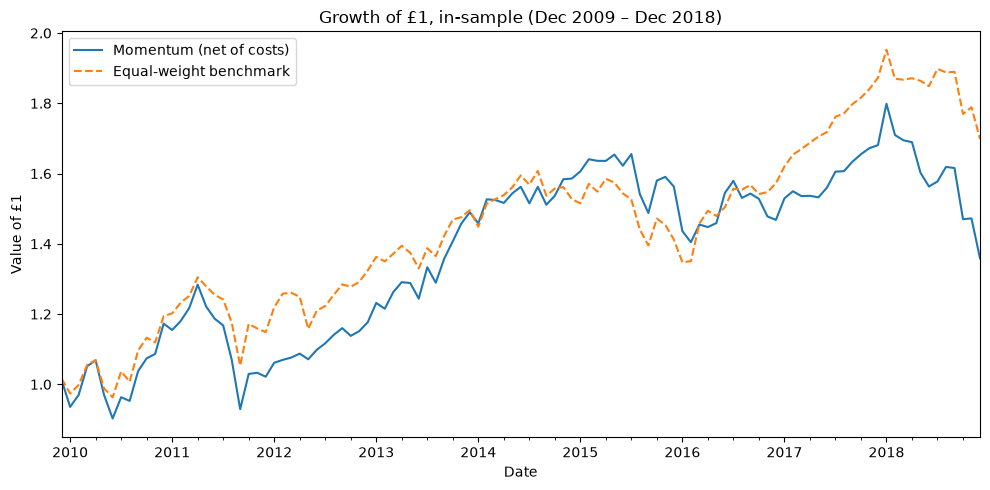

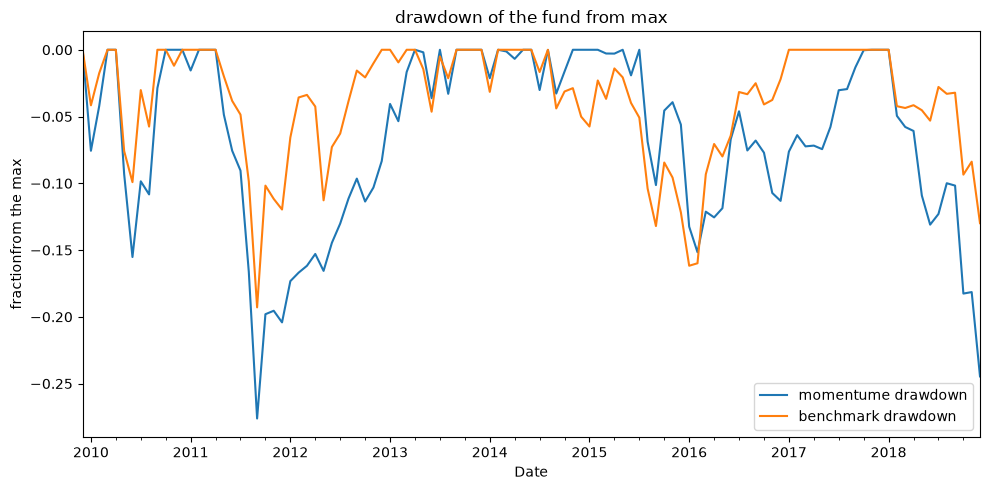

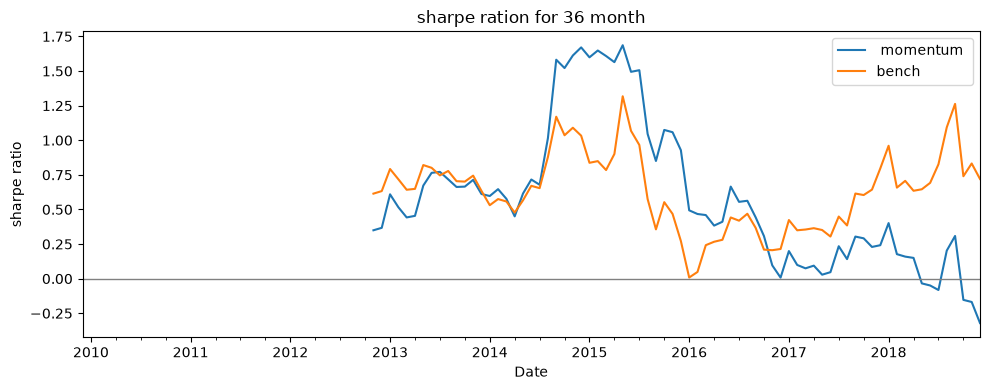

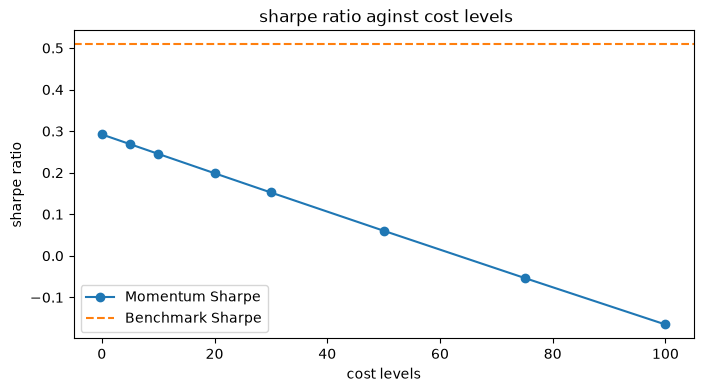

In [17]:
#Im sample

#plotting equitity curve Momentum aginst benchmark
fig , ax = plt.subplots(figsize = (10 , 5))
equity_is.plot(ax=ax, label="Momentum (net of costs)")
bench_equity_is.plot(ax=ax, label="Equal-weight benchmark", linestyle="--")
ax.legend(loc = "best")
ax.set_title("Growth of £1, in-sample (Dec 2009 – Dec 2018)")
ax.set_ylabel("Value of £1")
fig.tight_layout()
fig.savefig("chart1_equity_IS.png", dpi=150)

#plotting drawdown aginst benchmark
fig , ay = plt.subplots(figsize = (10 , 5))

ds_is = drawdown_series(net_is) 
ds_bench = drawdown_series(bench_is)

ds_is.plot(ax = ay , label = "momentume drawdown")
ds_bench.plot(ax = ay , label = "benchmark drawdown")
ay.legend(loc = "best")
ay.set_title("drawdown of the fund from max")
ay.set_ylabel("fractionfrom the max")
fig.tight_layout()
fig.savefig("drawdown series.png", dpi=150)

#rolling 36-month sharpe ratio
roll_mean = net_is.rolling(36).mean()*12
roll_vol = net_is.rolling(36).std()*(12**0.5)
roll_sharpe = roll_mean / roll_vol

roll_mean_b = bench_is.rolling(36).mean()*12
roll_vol_b = bench_is.rolling(36).std()*(12**0.5)
roll_sharpe_b = roll_mean_b / roll_vol_b

fig , az = plt.subplots( figsize = (10 , 4))
roll_sharpe.plot(ax = az , label = " momentum ")
roll_sharpe_b.plot( ax = az , label = "bench")
az.axhline(0, color="grey", linewidth=1)
az.legend( loc = "best")
az.set_ylabel ( "sharpe ratio")
az.set_title(" sharpe ration for 36 month ")
fig.tight_layout()
fig.savefig("rolling-36month sharpe ratio")

#sharpe ratio against cost_levels
cost_levels = [0, 5, 10, 20, 30, 50, 75, 100]
sharpes = []

for c in cost_levels:
    r = net_returns(c).loc[is_start:is_end]   # in-sample only
    sharpes.append(sharpe(r))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cost_levels, sharpes, marker="o", label="Momentum Sharpe")
ax.axhline(sharpe(bench_is), linestyle="--", color="tab:orange", label="Benchmark Sharpe")
ax.legend(loc= "best")
ax.set_xlabel("cost levels")
ax.set_ylabel("sharpe ratio")
ax.set_title(" sharpe ratio aginst cost levels")

plt.show()

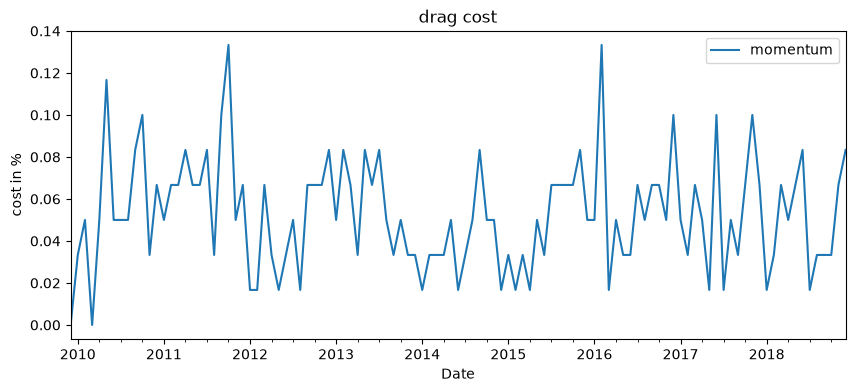

In [18]:
#cost sensistivity graph for each month
cost_is = turnover_is * bp/10000 *100
fig, aa =plt.subplots(figsize = (10,4))
cost_is.plot(ax = aa , label = "momentum")
aa.legend(loc = "best")
aa.set_title("drag cost")
aa.set_ylabel("cost in %")
plt.show()

In [19]:
def net_returns_full_range(cost_bps):
    cost = turnover * cost_bps/10000
    return (gross-cost.shift(1))



#deal with the out of sample
net_oos = (net_returns_full_range(bp)).loc["2019-01-31":]
bench_oos = monthly_return.mean(axis=1).loc["2019-01-31":]
turnover_oos = turnover.loc["2018-12-31":"2026-08-31"]

#making comparision table
table_oos = pd.DataFrame({
    "momentum":{
        "annualised return" : average_annual_return(net_oos) ,
        "annual volatility" : annual_volatility(net_oos),
        "sharpe ratio": sharpe(net_oos),
        "Max drawdown": max_down(net_oos),
        "hit rate": hit_rate(net_oos),
        "% beat the bench mark" : beat_bench(net_oos , bench_oos),
        "average annual turnover" : turnover_annual(turnover_oos),
    },
    "Benchmark":{
        "annualised return" : average_annual_return(bench_oos) ,
        "annual volatility" : annual_volatility(bench_oos),
        "sharpe ratio": sharpe(bench_oos),
        "Max drawdown": max_down(bench_oos),
        "hit rate": hit_rate(bench_oos),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }})
print(f"OUT OF SAMPLE: {net_oos.index[0].date()} to {net_oos.index[-1].date()} ({len(net_oos)} months)\n")
print(table_oos.round(3))

#calculating drag cost
print(f"\nCost drag at {bp} bp: "
      f"{(turnover_oos.mean()*12 * bp/10000) * 100:.2f}% per year")
table_oos.to_csv("results_out_of_sample.csv")

OUT OF SAMPLE: 2019-01-31 to 2026-09-30 (93 months)

                         momentum  Benchmark
annualised return           0.158      0.118
annual volatility           0.155      0.146
sharpe ratio                1.018      0.807
Max drawdown               -0.155     -0.232
hit rate                    0.656      0.645
% beat the bench mark       0.495        NaN
average annual turnover     5.548        NaN

Cost drag at 10 bp: 0.55% per year


In [20]:
#table for IS vs OOS
table_compare = pd.DataFrame({
    ("Out of sample" ,"momentum"):{
        "annualised return" : average_annual_return(net_oos) ,
        "annual volatility" : annual_volatility(net_oos),
        "sharpe ratio": sharpe(net_oos),
        "Max drawdown": max_down(net_oos),
        "hit rate": hit_rate(net_oos),
        "% beat the bench mark" : beat_bench(net_oos ,bench_oos),
        "average annual turnover" : turnover_annual(turnover_oos)},
       ("Out of sample" ,"Benchmark"):{
        "annualised return" : average_annual_return(bench_oos) ,
        "annual volatility" : annual_volatility(bench_oos),
        "sharpe ratio": sharpe(bench_oos),
        "Max drawdown": max_down(bench_oos),
        "hit rate": hit_rate(bench_oos),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }, 
        ("In sample" ,"momentum"):{
        "annualised return" : average_annual_return(net_is) ,
        "annual volatility" : annual_volatility(net_is),
        "sharpe ratio": sharpe(net_is),
        "Max drawdown": max_down(net_is),
        "hit rate": hit_rate(net_is),
        "% beat the bench mark" : beat_bench(net_is , bench_is),
        "average annual turnover" : turnover_annual(turnover_is),
    },
    ("In sample" ,"Benchmark"):{
        "annualised return" : average_annual_return(bench_is) ,
        "annual volatility" : annual_volatility(bench_is),
        "sharpe ratio": sharpe(bench_is),
        "Max drawdown": max_down(bench_is),
        "hit rate": hit_rate(bench_is),
        "% beat the bench mark" : float("nan"),
        "average annual turnover" : float("nan")
    }})

print(table_compare)
table_compare.to_csv("results_compare.csv")

                        Out of sample           In sample          
                             momentum Benchmark  momentum Benchmark
annualised return            0.158027  0.118168  0.034326  0.060079
annual volatility            0.155177  0.146401  0.139931  0.118148
sharpe ratio                 1.018368  0.807159  0.245303  0.508508
Max drawdown                -0.154786 -0.231729 -0.276155 -0.192923
hit rate                     0.655914  0.645161  0.587156  0.605505
% beat the bench mark        0.494624       NaN  0.467890       NaN
average annual turnover      5.548387       NaN  6.330275       NaN


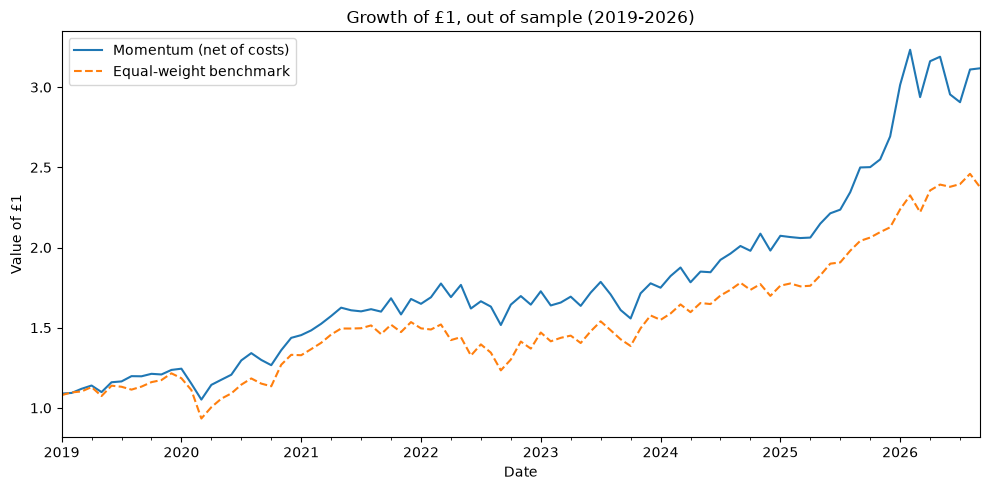

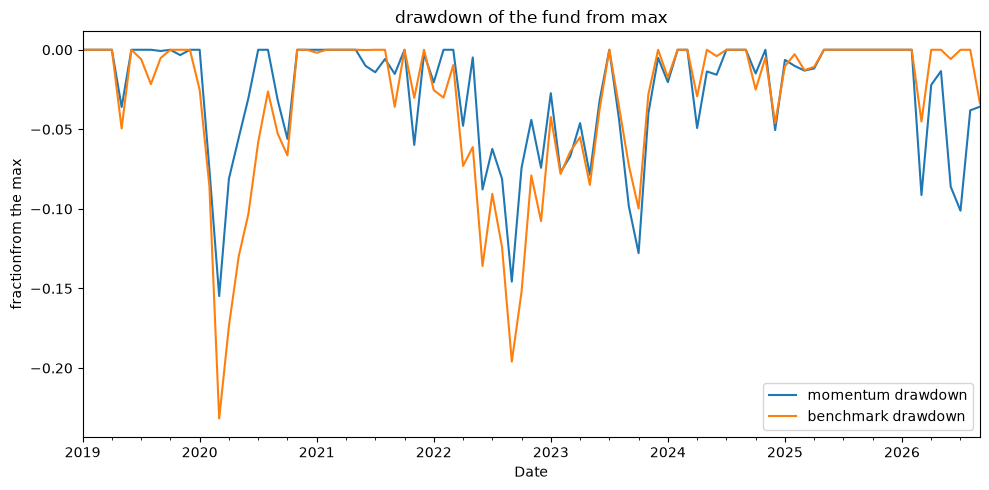

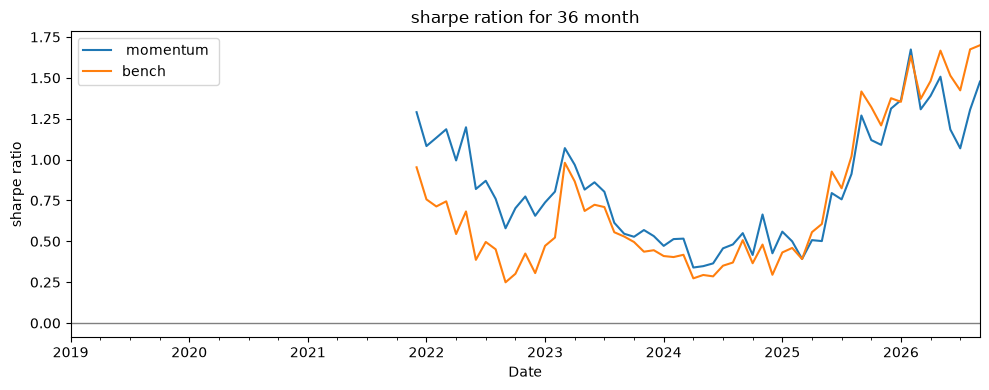

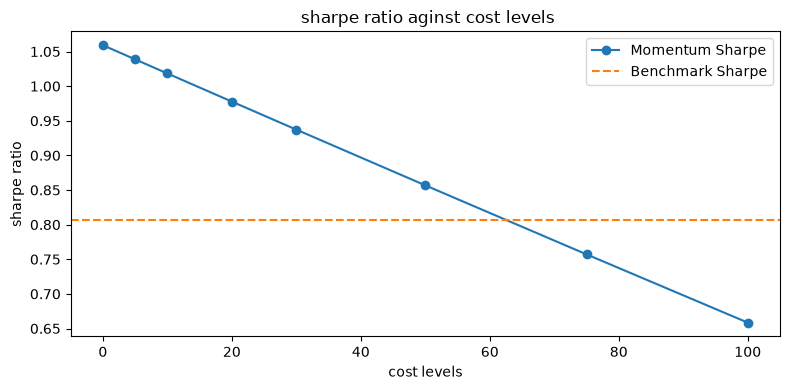

In [25]:
#Out of sample

#plotting equitity curve Momentum aginst benchmark
equity_oos = (1+net_oos).cumprod()
bench_equity_oos = (1+bench_oos).cumprod()
fig , ab = plt.subplots(figsize = (10 , 5))
equity_oos.plot(ax=ab, label="Momentum (net of costs)")
bench_equity_oos.plot(ax=ab, label="Equal-weight benchmark", linestyle="--")
ab.legend(loc = "best")
ab.set_title("Growth of £1, out of sample (2019-2026)")
ab.set_ylabel("Value of £1")
fig.tight_layout()
fig.savefig("momentum aginst bench equity (out of sample).png", dpi = 150)


#plotting drawdown aginst benchmark
fig , ac = plt.subplots(figsize = (10 , 5))

ds_oos = drawdown_series(net_oos) 
ds_bench_oos = drawdown_series(bench_oos)

ds_oos.plot(ax = ac , label = "momentum drawdown")
ds_bench_oos.plot(ax = ac , label = "benchmark drawdown")
ac.legend(loc = "best")
ac.set_title("drawdown of the fund from max")
ac.set_ylabel("fractionfrom the max")
fig.tight_layout()
fig.savefig("momentum aginst benchmark , (out of sample drawdown).png" , dpi =150)

#rolling 36-month sharpe ratio
roll_mean_oos = net_oos.rolling(36).mean()*12
roll_vol_oos = net_oos.rolling(36).std()*(12**0.5)
roll_sharpe_oos = roll_mean_oos / roll_vol_oos

roll_mean_b_oos = bench_oos.rolling(36).mean()*12
roll_vol_b_oos = bench_oos.rolling(36).std()*(12**0.5)
roll_sharpe_b_oos = roll_mean_b_oos / roll_vol_b_oos

fig , ad = plt.subplots( figsize = (10 , 4))
roll_sharpe_oos.plot(ax = ad , label = " momentum ")
roll_sharpe_b_oos.plot( ax = ad , label = "bench")
ad.axhline(0, color="grey", linewidth=1)
ad.legend( loc = "best")
ad.set_ylabel ( "sharpe ratio")
ad.set_title(" sharpe ration for 36 month ")
fig.tight_layout()
fig.savefig("rolling 36 month sharp ratio (out of sample).png" , dpi = 150)

#sharpe ratio against cost_levels
cost_levels = [0, 5, 10, 20, 30, 50, 75, 100]
sharpes = []

for bps in cost_levels:
    r = net_returns_full_range(bps).loc["2019-01-31":]   # in-sample only
    sharpes.append(sharpe(r))

fig, ae = plt.subplots(figsize=(8, 4))
ae.plot(cost_levels, sharpes, marker="o", label="Momentum Sharpe")
ae.axhline(sharpe(bench_oos), linestyle="--", color="tab:orange", label="Benchmark Sharpe")
ae.legend(loc= "best")
ae.set_xlabel("cost levels")
ae.set_ylabel("sharpe ratio")
ae.set_title(" sharpe ratio aginst cost levels")
fig.tight_layout()
fig.savefig("sharpe ratio aginst cost levels (out of sample).png" , dpi = 150)

plt.show()

Year-by-year returns (%). Note: 2026 is a partial year (Jan-Sep).

      Momentum  Benchmark  Difference  Momentum won         Period
Date                                                              
2010      15.9       17.5        -1.7         False      In-sample
2011     -12.9       -3.8        -9.1         False      In-sample
2012      15.2       15.3        -0.1         False      In-sample
2013      26.6       12.9        13.6          True      In-sample
2014       6.5        2.1         4.4          True      In-sample
2015      -1.5       -7.5         6.1          True      In-sample
2016      -6.1       11.4       -17.4         False      In-sample
2017      14.5       19.1        -4.6         False      In-sample
2018     -19.2       -9.3        -9.9         False      In-sample
2019      23.7       21.6         2.1          True  Out-of-sample
2020      16.2        9.5         6.7          True  Out-of-sample
2021      16.9       15.3         1.5          True  Out-of-sa

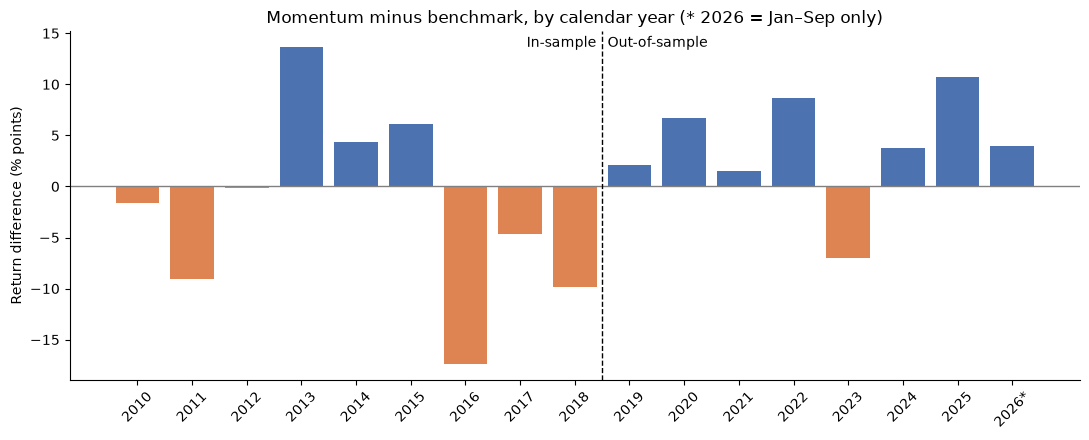

In [22]:
# =====================================================================
# STAGE 5, PART B: WALK-FORWARD, YEAR BY YEAR
# The strategy has no fitted parameters (12-1, top 20%, equal weight were
# all fixed in advance), so walk-forward here means: test it one calendar
# year at a time, and see whether results are consistent or come from a
# few years.
# =====================================================================

# Full-period monthly returns (Dec 2009 - Sep 2026), at the frozen 10 bp
net_full = net_returns_full_range(bp).loc[is_start:]
bench_full = bench.loc[is_start:]


def compound(r):
    """Turn one year's monthly returns into that year's total return."""
    return (1 + r).prod() - 1


# Group the months into calendar years and compound each year
# ("YE" = year-end; use "Y" if your pandas version is older)
yearly = pd.DataFrame({
    "Momentum": net_full.resample("YE").apply(compound),
    "Benchmark": bench_full.resample("YE").apply(compound),
})
yearly.index = yearly.index.year      # 2010-12-31 -> 2010, easier to read
yearly = yearly.loc[2010:]            # drop 2009: only 1 month (Dec)

yearly["Difference"] = yearly["Momentum"] - yearly["Benchmark"]
yearly["Momentum won"] = yearly["Difference"] > 0
yearly["Period"] = ["In-sample" if y <= 2018 else "Out-of-sample" for y in yearly.index]

print("Year-by-year returns (%). Note: 2026 is a partial year (Jan-Sep).\n")
show = (yearly[["Momentum", "Benchmark", "Difference"]] * 100).round(1)
print(show.join(yearly[["Momentum won", "Period"]]).to_string())

# ---- Summary: how consistent was momentum in each period? ----
summary = yearly.groupby("Period").agg(
    years=("Difference", "size"),
    years_won=("Momentum won", "sum"),
    avg_difference=("Difference", "mean"),
    best_year=("Difference", "max"),
    worst_year=("Difference", "min"),
)
summary["win_rate"] = summary["years_won"] / summary["years"]
print("\nSummary by period:")
print(summary.round(3).to_string())

# ---- Concentration check: does the OOS win depend on one or two years? ----
oos = yearly.loc[yearly["Period"] == "Out-of-sample", "Difference"]
print("\nOut-of-sample yearly differences, best to worst (%):")
print((oos.sort_values(ascending=False) * 100).round(1).to_string())
print(f"\nAverage OOS difference: {oos.mean() * 100:.1f}% a year")
print(f"Without the single best year: {oos.drop(oos.idxmax()).mean() * 100:.1f}% a year")

yearly.to_csv("results_yearly_walk_forward.csv")

# ---- Chart: yearly difference, momentum minus benchmark ----
colours = ["#4C72B0" if d > 0 else "#DD8452" for d in yearly["Difference"]]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(yearly.index, yearly["Difference"] * 100, color=colours)
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(2018.5, color="black", linestyle="--", linewidth=1)   # IS / OOS split
ax.text(2018.4, ax.get_ylim()[1] * 0.9, "In-sample", ha="right")
ax.text(2018.6, ax.get_ylim()[1] * 0.9, "Out-of-sample", ha="left")
ax.set_xticks(yearly.index)
ax.set_xticklabels([f"{y}*" if y == 2026 else str(y) for y in yearly.index], rotation=45)
ax.set_title("Momentum minus benchmark, by calendar year (* 2026 = Jan–Sep only)")
ax.set_ylabel("Return difference (% points)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("chart_yearly_difference.png", dpi=150)
plt.show()